In [43]:
import numpy as np
import matplotlib.pyplot as plt
from starter_pack.code import utils, align_images

from convolution import conv2d_sep, gaussian_kernel
from filters_helpers import to_gray, signed_to_display
from Hybrid_img import (
    make_hybrid,
    compute_fft_log_magnitude
)

In [ ]:
cat = utils.load_image("starter_pack\images\part2_frequencies\hybrid_cat.jpg")
man = utils.load_image("starter_pack\images\part2_frequencies\hybrid_man.jpg")
%matplotlib tk
pts_man = align_images.pick_points(man)
pts_cat = align_images.pick_points(cat)
%matplotlib inline

cat = align_images.align_images(man, cat, pts_man, pts_cat)
print("Man shape:", man.shape)
print("Cat shape:", cat.shape)

<>:1: SyntaxWarning: invalid escape sequence '\i'
<>:2: SyntaxWarning: invalid escape sequence '\i'
<>:1: SyntaxWarning: invalid escape sequence '\i'
<>:2: SyntaxWarning: invalid escape sequence '\i'
C:\Users\bodyy\AppData\Local\Temp\ipykernel_14024\2609541963.py:1: SyntaxWarning: invalid escape sequence '\i'
  cat = utils.load_image("starter_pack\images\part2_frequencies\hybrid_cat.jpg")
C:\Users\bodyy\AppData\Local\Temp\ipykernel_14024\2609541963.py:2: SyntaxWarning: invalid escape sequence '\i'
  man = utils.load_image("starter_pack\images\part2_frequencies\hybrid_man.jpg")


Man shape: (1024, 732, 3)
Cat shape: (1024, 732, 3)


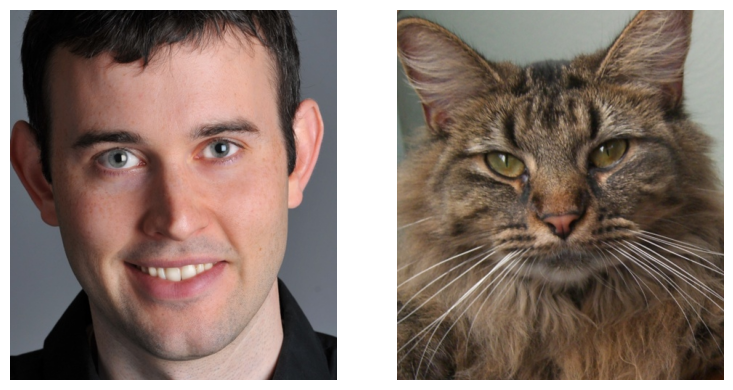

In [60]:
y1, y2 = 140, 650
x1, x2 = 150, 600

man_cropped = man[y1:y2, x1:x2]
cat_cropped = cat_aligned[y1:y2, x1:x2]
utils.show(man_cropped,cat_cropped)

In [64]:
sigma_low = 7.0
sigma_high = 4.0

man_lp, cat_hp, hybrid = make_hybrid(man_cropped, cat_cropped, sigma_low, sigma_high)
utils.save_image("hybrid_man_cat.png", hybrid)

In [104]:
rayes = utils.load_image("elrayes.jpg")
lion = utils.load_image("lion.jpg")

In [108]:
%matplotlib tk
pts_rayes = align_images.pick_points(rayes)
pts_lion = align_images.pick_points(lion)
%matplotlib inline

lion = align_images.align_images(rayes, lion, pts_rayes, pts_lion)
print("Man shape:", rayes.shape)
print("Cat shape:", lion.shape)

Man shape: (633, 485, 3)
Cat shape: (633, 485, 3)


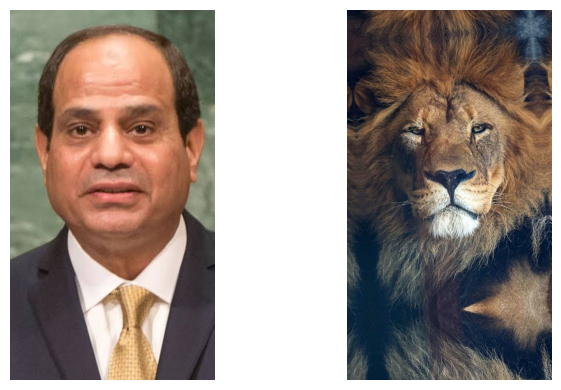

In [115]:
y1, y2 = 0, 650
x1, x2 = 50, 400

rayes_cropped = rayes[y1:y2, x1:x2]
lion_cropped = lion[y1:y2, x1:x2]
utils.show(rayes_cropped,lion_cropped)

In [134]:
rayes_lp, lion_hp, hybrid = make_hybrid(rayes_cropped, lion_cropped, sigma_low, sigma_high)
utils.save_image("hybrid_rayes_lion.png", hybrid)

In [125]:
frog = utils.load_image("frog.jpg")
deer = utils.load_image("deer.jpg")

In [126]:
%matplotlib tk
pts_deer = align_images.pick_points(deer)
pts_frog = align_images.pick_points(frog)
%matplotlib inline

deer = align_images.align_images(frog, deer, pts_frog, pts_deer)
print("Man shape:", deer.shape)
print("Cat shape:", frog.shape)

Man shape: (1080, 720, 3)
Cat shape: (1080, 720, 3)


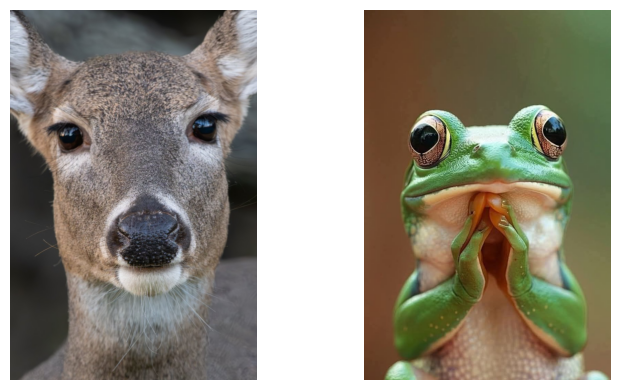

In [132]:
y1, y2 = 0, 720
x1, x2 = 0, 1080

deer_cropped = deer[y1:y2, x1:x2]
frog_cropped = frog[y1:y2, x1:x2]
utils.show(deer,frog)

In [133]:
deer_lp, frog_hp, hybrid = make_hybrid(deer, frog, sigma_low, sigma_high)
utils.save_image("hybrid_deer_frog.png", hybrid)

<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\s'
C:\Users\bodyy\AppData\Local\Temp\ipykernel_14024\798421647.py:31: SyntaxWarning: invalid escape sequence '\s'
  f"Man, low-pass ($\sigma$={sigma_low})",
C:\Users\bodyy\AppData\Local\Temp\ipykernel_14024\798421647.py:32: SyntaxWarning: invalid escape sequence '\s'
  f"Cat, high-pass ($\sigma$={sigma_high})",


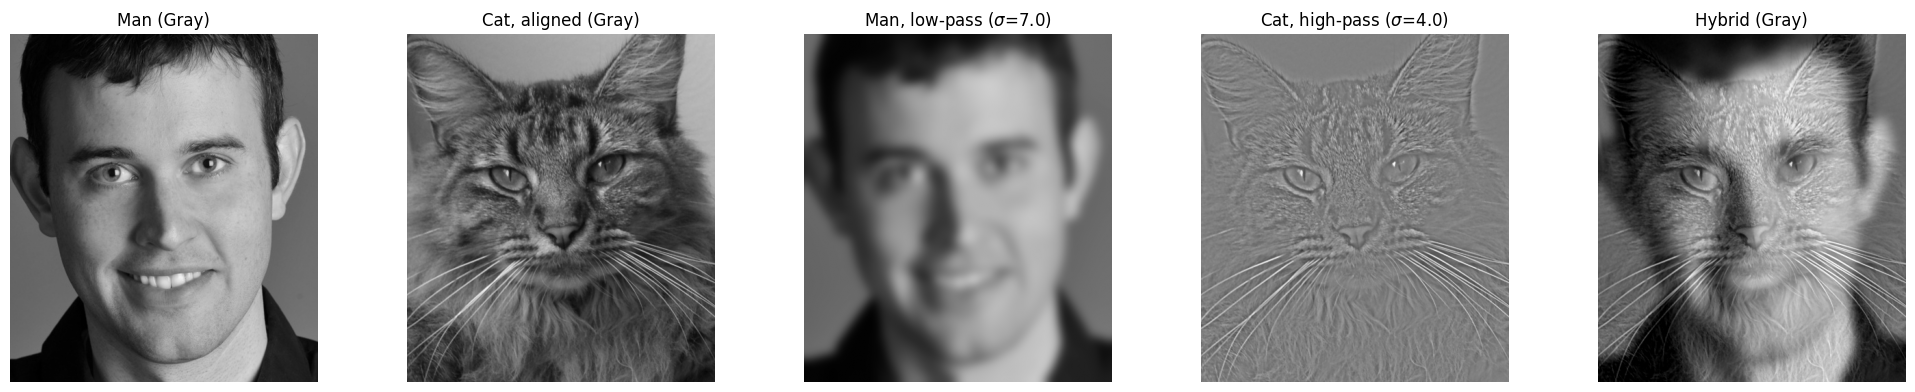

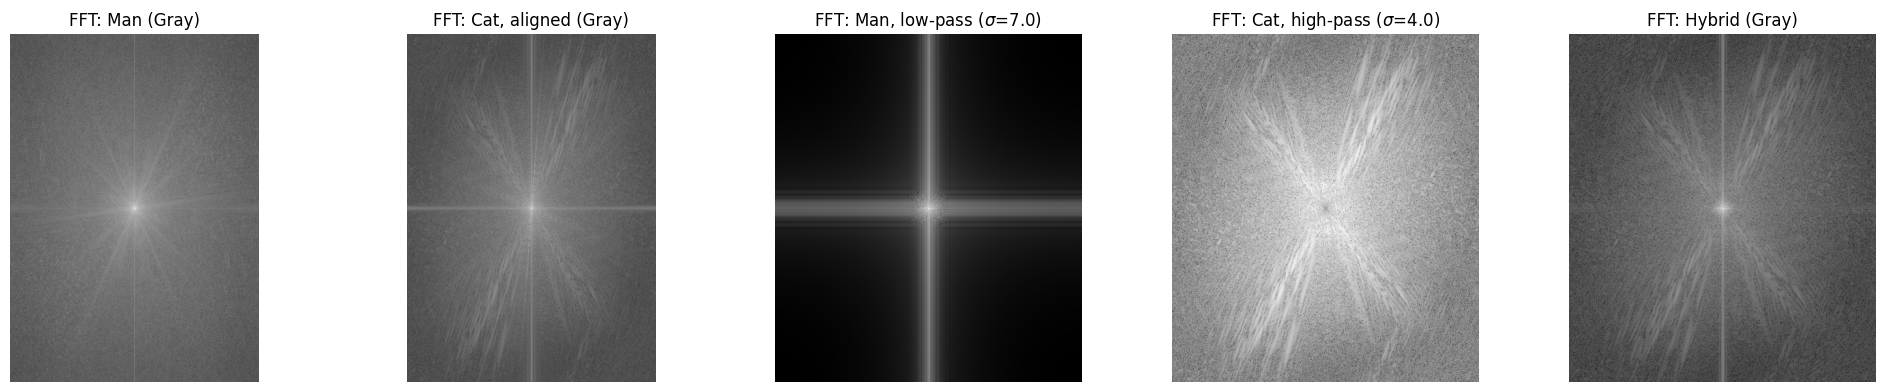

In [65]:
cat_hp_vis = np.clip(cat_hp + 0.5, 0.0, 1.0)
gray_man        = to_gray(man_cropped)
gray_cat        = to_gray(cat_cropped)
gray_man_lp     = to_gray(man_lp)
gray_cat_hp     = to_gray(cat_hp_vis)
gray_hybrid     = to_gray(hybrid)

fft_man    = np.log(np.abs(np.fft.fftshift(np.fft.fft2(to_gray(man)))))
fft_cat    = np.log(np.abs(np.fft.fftshift(np.fft.fft2(to_gray(cat_aligned)))))
fft_man_lp = np.log(np.abs(np.fft.fftshift(np.fft.fft2(to_gray(man_lp)))))
fft_cat_hp = np.log(np.abs(np.fft.fftshift(np.fft.fft2(to_gray(cat_hp)))))
fft_hybrid = np.log(np.abs(np.fft.fftshift(np.fft.fft2(to_gray(hybrid)))))

def normalize_fft_for_display(fft_mag):
    f_min = fft_mag.min()
    f_max = fft_mag.max()
    if f_max > f_min:
        return (fft_mag - f_min) / (f_max - f_min)
    return np.zeros_like(fft_mag)
ffts_normalized = [
    normalize_fft_for_display(fft_man),
    normalize_fft_for_display(fft_cat),
    normalize_fft_for_display(fft_man_lp),
    normalize_fft_for_display(fft_cat_hp),
    normalize_fft_for_display(fft_hybrid)
]
grays_top = [gray_man, gray_cat, gray_man_lp, gray_cat_hp, gray_hybrid]
titles = [
    "Man (Gray)", 
    "Cat, aligned (Gray)", 
    f"Man, low-pass ($\sigma$={sigma_low})", 
    f"Cat, high-pass ($\sigma$={sigma_high})", 
    "Hybrid (Gray)"
]
utils.show(*grays_top, titles=titles)
fft_titles = [f"FFT: {t}" for t in titles]
utils.show(*ffts_normalized, titles=fft_titles)